# Module 3 — Phase 1: ELA + Metadata Forensic Analyzer
**AI Passport Screening System — India → Bangladesh Border Checkpoint**

This notebook tests:
1. ELA (Error Level Analysis)
2. Image Metadata Extraction
3. Combined Forensic Pipeline
4. Error handling for invalid paths

> **Reminder:** ELA is a forensic *visualisation* tool. It highlights compression
> inconsistencies and does NOT prove tampering on its own.

## 0. Setup — path configuration
Edit `IMAGE_PATH` to test different passport images.

In [1]:
import sys, os
# Make sure the project root is in sys.path when running from notebooks/
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# ── EDIT THIS to select a passport image ──────────────────────────
IMAGE_PATH = os.path.join(PROJECT_ROOT, 'passport', 'passport1.jpg')
# ──────────────────────────────────────────────────────────────────

print('Project root:', PROJECT_ROOT)
print('Image path  :', IMAGE_PATH)
print('Image exists:', os.path.exists(IMAGE_PATH))

Project root: C:\Users\priya\Desktop\prototype
Image path  : C:\Users\priya\Desktop\prototype\passport\passport1.jpg
Image exists: True


## 1. ELA Analysis

In [2]:
from app.tampering.ela_analyzer import run_ela

ela_result = run_ela(
    source=IMAGE_PATH,
    quality=90,
    scale=15,
    save_path=os.path.join(PROJECT_ROOT, 'data', 'forensics', 'ela_output', 'test_ela.png'),
)

print('Success      :', ela_result['success'])
print('Format       :', ela_result['source_format'])
print('Converted    :', ela_result['converted'])
print('Mean ELA     :', ela_result['mean_ela'])
print('Max ELA      :', ela_result['max_ela'])
print('Quality used :', ela_result['quality_used'])
print('Scale used   :', ela_result['scale_used'])
print('Saved to     :', ela_result['save_path'])
if ela_result['error']:
    prSuccess      : True
Format       : JPEG
Converted    : False
Mean ELA     : 0.07451372593641281
Max ELA      : 6.0
Quality used : 90
Scale used   : 15
Saved to     : C:\Users\priya\Desktop\prototype\data\forensics\ela_output\test_ela.pngint('Error        :', ela_result['error'])

Success      : True
Format       : JPEG
Converted    : False
Mean ELA     : 0.07451372593641281
Max ELA      : 6.0
Quality used : 90
Scale used   : 15
Saved to     : C:\Users\priya\Desktop\prototype\data\forensics\ela_output\test_ela.png


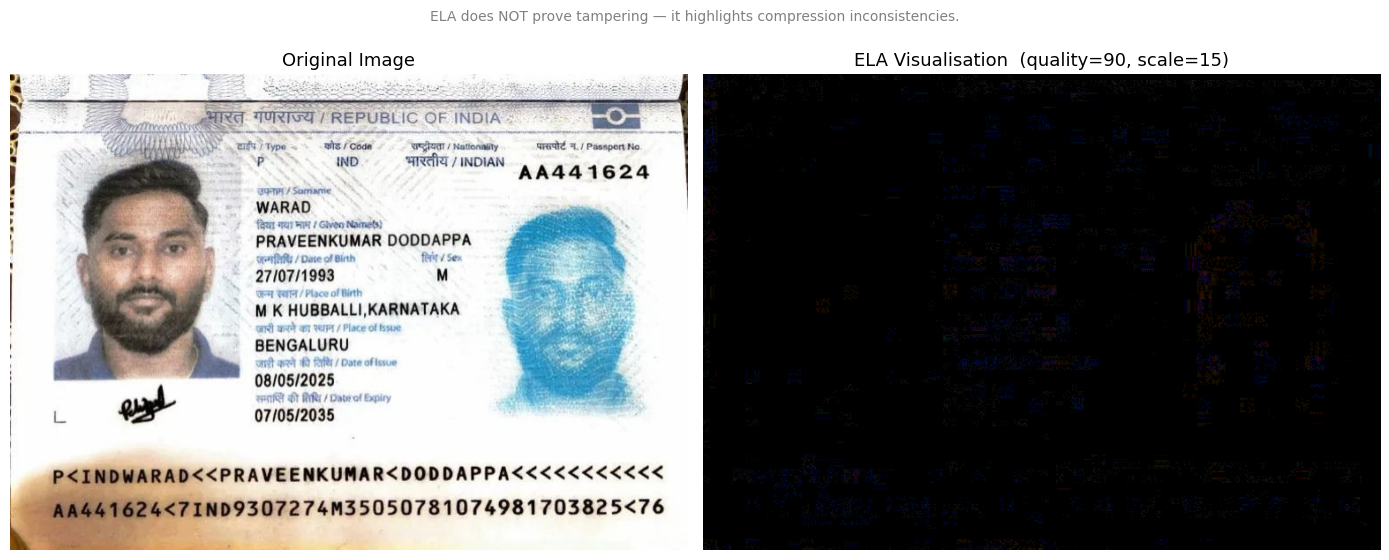

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

if ela_result['success'] and ela_result['ela_image'] is not None:
    original = Image.open(IMAGE_PATH).convert('RGB')
    ela_img  = ela_result['ela_image']

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(original)
    axes[0].set_title('Original Image', fontsize=13)
    axes[0].axis('off')

    axes[1].imshow(ela_img)
    axes[1].set_title(
        f'ELA Visualisation  (quality={ela_result["quality_used"]}, '
        f'scale={ela_result["scale_used"]})',
        fontsize=13
    )
    axes[1].axis('off')

    plt.suptitle(
        'ELA does NOT prove tampering — it highlights compression inconsistencies.',
        fontsize=10, color='gray'
    )
    plt.tight_layout()
    plt.show()
else:
    print('ELA did not succeed; no image to display.')
    print('Error:', ela_result.get('error'))

## 2. Metadata Analysis

In [4]:
import json
from app.tampering.metadata_analyzer import run_metadata_analysis

meta_result = run_metadata_analysis(IMAGE_PATH)

print('=== IMAGE INFO ===')
print(json.dumps(meta_result['image_info'], indent=2, default=str))

print('\n=== EXIF FIELDS (curated) ===')
print(json.dumps(meta_result['exif_fields'], indent=2, default=str))

print('\n=== OBSERVATIONS (informational only) ===')
for i, obs in enumerate(meta_result['observations'], 1):
    print(f'  [{i}] {obs}')

if meta_result.get('error'):
    print('\nError:', meta_result['error'])

=== IMAGE INFO ===
{
  "format": "JPEG",
  "width": 768,
  "height": 540,
  "mode": "RGB",
  "file_size": 111386
}

=== EXIF FIELDS (curated) ===
{}

=== OBSERVATIONS (informational only) ===
  [1] No EXIF metadata found. This is normal for PNG files, screenshots, or images that have been re-exported through tools that strip metadata.


### 2b. Full raw EXIF dump (optional)

In [5]:
print('=== ALL RAW EXIF TAGS ===')
raw = meta_result.get('exif_raw', {})
if raw:
    print(json.dumps(raw, indent=2, default=str))
else:
    print('(No EXIF data found in this image)')

=== ALL RAW EXIF TAGS ===
(No EXIF data found in this image)


## 3. Combined Forensic Pipeline

In [6]:
from app.tampering.tampering_pipeline import run_forensic_pipeline

report = run_forensic_pipeline(
    image_path=IMAGE_PATH,
    ela_quality=90,
    ela_scale=15,
    save_ela=True,
)

print('=== FORENSIC PIPELINE REPORT ===')
print('Status    :', report['status'])
print('Timestamp :', report['timestamp'])
print()

print('--- INPUT ---')
print(json.dumps(report['input'], indent=2))

print('\n--- METADATA ---')
print(json.dumps(report['metadata'], indent=2, default=str))

print('\n--- ELA ---')
print(json.dumps(report['ela'], indent=2, default=str))

if report['warnings']:
    print('\n--- WARNINGS ---')
    for w in report['warnings']:
        print(' *', w)

if report['errors']:
    print('\n--- ERRORS ---')
    for e in report['errors']:
        print(' !', e)

=== FORENSIC PIPELINE REPORT ===
Status    : ok
Timestamp : 2026-09-20T10:54:07.950164Z

--- INPUT ---
{
  "path": "C:\\Users\\priya\\Desktop\\prototype\\passport\\passport1.jpg",
  "filename": "passport1.jpg"
}

--- METADATA ---
{
  "success": true,
  "image_info": {
    "format": "JPEG",
    "width": 768,
    "height": 540,
    "mode": "RGB",
    "file_size": 111386
  },
  "exif_fields": {},
  "observations": [
    "No EXIF metadata found. This is normal for PNG files, screenshots, or images that have been re-exported through tools that strip metadata."
  ],
  "error": null
}

--- ELA ---
{
  "success": true,
  "mean_ela": 0.07451372593641281,
  "max_ela": 6.0,
  "quality_used": 90,
  "scale_used": 15,
  "source_format": "JPEG",
  "converted": false,
  "ela_image_path": "data\\forensics\\ela_output\\passport1_ela_q90.png",
  "error": null
}


## 4. Error Handling — invalid path

In [7]:
# --- ELA with non-existent file ---
bad_result = run_ela(source='/does/not/exist/fake_passport.jpg')
print('ELA success :', bad_result['success'])
print('ELA error   :', bad_result['error'])

ELA success : False
ELA error   : Image not found: \does\not\exist\fake_passport.jpg


In [8]:
# --- Metadata with non-existent file ---
bad_meta = run_metadata_analysis('/does/not/exist/fake.jpg')
print('Meta success :', bad_meta['success'])
print('Meta error   :', bad_meta['error'])

Meta success : False
Meta error   : Image not found: \does\not\exist\fake.jpg


In [9]:
# --- Pipeline with non-existent file ---
bad_report = run_forensic_pipeline('/does/not/exist/fake.jpg')
print('Pipeline status :', bad_report['status'])
print('Pipeline errors :', bad_report['errors'])

Pipeline status : failed
Pipeline errors : ['Image not found: \\does\\not\\exist\\fake.jpg']


## 5. Batch — run all 13 passport images
Useful to spot patterns across your dataset.

In [10]:
import glob

passport_dir = os.path.join(PROJECT_ROOT, 'passport')
images = sorted(glob.glob(os.path.join(passport_dir, '*.jpg')))
print(f'Found {len(images)} passport images.\n')

summary_rows = []
for img_path in images:
    r = run_forensic_pipeline(img_path, save_ela=False)
    ela  = r['ela']
    meta = r['metadata']
    row = {
        'file':       os.path.basename(img_path),
        'status':     r['status'],
        'format':     meta.get('image_info', {}).get('format'),
        'size_kb':    round((meta.get('image_info', {}).get('file_size') or 0) / 1024, 1),
        'mean_ela':   round(ela.get('mean_ela') or 0, 3),
        'max_ela':    round(ela.get('max_ela') or 0, 1),
        'n_obs':      len(meta.get('observations', [])),
        'software':   meta.get('exif_fields', {}).get('software', ''),
        'has_gps':    meta.get('exif_fields', {}).get('gps_present', False),
    }
    summary_rows.append(row)
    print(f"{row['file']:20s}  mean_ELA={row['mean_ela']:6.3f}  max_ELA={row['max_ela']:5.1f}  "
          f"format={row['format']:5s}  obs={row['n_obs']}")

print('\nDone.')

Found 13 passport images.

passport1.jpg         mean_ELA= 0.075  max_ELA=  6.0  format=JPEG   obs=1
passport10.jpg        mean_ELA= 0.005  max_ELA=  3.0  format=JPEG   obs=1
passport11.jpg        mean_ELA= 0.036  max_ELA=  8.0  format=JPEG   obs=1
passport12.jpg        mean_ELA= 0.333  max_ELA=  6.0  format=JPEG   obs=1
passport13.jpg        mean_ELA= 0.620  max_ELA= 18.0  format=JPEG   obs=1
passport2.jpg         mean_ELA= 1.418  max_ELA= 14.0  format=JPEG   obs=1
passport3.jpg         mean_ELA= 0.023  max_ELA=  6.0  format=JPEG   obs=1
passport4.jpg         mean_ELA= 0.088  max_ELA=  7.0  format=JPEG   obs=1
passport5.jpg         mean_ELA= 0.026  max_ELA=  4.0  format=JPEG   obs=1
passport6.jpg         mean_ELA= 0.006  max_ELA=  3.0  format=JPEG   obs=1
passport7.jpg         mean_ELA= 0.037  max_ELA=  5.0  format=JPEG   obs=1
passport8.jpg         mean_ELA= 0.006  max_ELA=  2.0  format=JPEG   obs=1
passport9.jpg         mean_ELA= 0.030  max_ELA=  7.0  format=JPEG   obs=1

Done.
